# ML Pipeline and ML Modeling

The ML pipeline will be created in this notebook. This will include the data cleaning, feature engineering, and machine learning modeling of the data.

The pipeline workflow will be:
```
Raw data
   │
   ├── deterministic cleaning
   │
   ├── deterministic feature engineering
   │
   ▼
Train / Test split
   │
   ├───────────────┐
   ▼               ▼
TRAIN             TEST
   │               │
   ▼               │
Fit preprocessing  │
   │               │
   ├── TargetEncoder
   ├── Imputers
   ├── Scalers
   ├── KMeans
   │               │
   ▼               ▼
Transform TRAIN   Transform TEST
   │               │
   └───────┬───────┘
           ▼
       ML Model
```

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Others
import os
import re

sns.set_theme(
    style='darkgrid',
    context='notebook',
    palette='deep'
)
sns.despine()

<Figure size 640x480 with 0 Axes>

In [2]:
root = os.path.dirname(os.getcwd())
data_dir = os.path.join(root, 'data/raw/', 'PH_Housing.csv')
data = pd.read_csv(data_dir)

### Deterministic Cleaning and Feature Engineering

In [3]:
# Area flag for NCR, Near NCR, Cebu. List for cities

ncr = [
    'caloocan',
    'las pinas',
    'makati',
    'malabon',
    'mandaluyong',
    'manila',
    'marikina',
    'muntinlupa',
    'navotas',
    'paranaque',
    'pateros',
    'pasay',
    'pasig',
    'quezon city',
    'san juan',
    'taguig',
    'valenzuela',
]

metro_cebu = [
    'cebu',
    'mandaue',
    'lapu-lapu',
    'consolacion',
    'talisay',
    'minglanilla',
    'apas',
    'lahug',
]

near_ncr = [
    # Cavite
    'silang',
    'carmona',
    'alfonso',
    'tagaytay',
    'dasmarinas',
    'bacoor',
    'general trias',
    'imus',
    'trece martires',
    'tanza',
    'kawit',
    'rosario',
    'naic',

    # Laguna
    'los banos',
    'cabuyao',
    'santa rosa',
    'sta rosa city laguna',
    'calamba',
    'binan',
    'san pablo',
    'pagsanjan',
    'pila',
    'lumban',
    'majayjay',
    'calauan',

    # Rizal
    'antipolo',
    'taytay',
    'cainta',
    'san mateo',
    'angono',
    'binangonan',
    'teresa',

    # Bulacan
    'san jose del monte',
    'marilao',
    'pulilan',
    'malolos',
    'baliuag',
    'plaridel',
    'santa maria',
    'meycauayan',
    'pandi',
    'hagonoy',
    'paombong',
    'san rafael',
    'bulacan',
]

# House type
house_types = ['mansion', 'beach house', 'rest house', 'bungalow', 'townhouse', 'villa', 'rowhouse', 'detached', 'attached', \
            'shophouse', 'duplex', 'triplex', 'condominium']

In [4]:
# Parser functions

def parse_loc(location):
    if pd.isna(location):
        return 'missing', 'missing'
        
    parsed = [part.strip().lower() for part in location.split(',')]
    
    if len(parsed) >= 2:
        locality = parsed[-2]
        city = parsed[-1]
    elif len(parsed) == 1:
        locality = 'missing'
        city = parsed[-1]
    else:
        locality = 'missing'
        city = 'missing'

    return locality, city

def parse_type(description):
    if pd.isna(description):
        return 'others'

    for house_type in house_types:
        match = re.search(rf'\b({re.escape(house_type)})s?\b', description, flags=re.IGNORECASE)
        if match:
            return house_type.lower()

    return 'others'

def parse_two_storey(description):
    if pd.isna(description):
        return 0

    description = description.lower()
    if re.search(r'2[-\s]?storeys?', description) or re.search(r'two[-\s]?storeys?', description):
        return 1
    else:
        return 0

def parse_three_storey(description):
    if pd.isna(description):
        return 0

    description = description.lower()
    if re.search(r'3[-\s]?storeys?', description) or re.search(r'three[-\s]?storeys?', description):
        return 1
    else:
        return 0

def parse_elite(row):
    if pd.isna(row['description']) or pd.isna(row['location']):
        return 0

    pattern_forbes = r'\bforbes park\b'
    pattern_ayala = r'\bayala alabang\b'

    description = row['description'].lower()
    location = row['location'].lower()

    if re.search(pattern_ayala, location, flags=re.IGNORECASE) or re.search(pattern_ayala, description, flags=re.IGNORECASE):
        return 1
    elif re.search(pattern_forbes, location, flags=re.IGNORECASE) or re.search(pattern_forbes, description, flags=re.IGNORECASE):
        return 1
    else:
        return 0

In [5]:
# Pipeline functions

def det_cleaning(data):
    data = data.rename(columns={
        'Description': 'description',
        'Location': 'location',
        'Price': 'price',
        'Bedrooms': 'bedrooms',
        'Bathrooms': 'bathrooms',
        'Floor Area': 'floor_area',
        'Land Area': 'land_area',
        'Latitude': 'latitude',
        'Longitude': 'longitude'
    })

    data = data.drop(columns='HouseID')
    data = data.dropna(subset=['price'])
    data.loc[data['location'].isna(), 'location'] = 'Likha Residences, Muntinlupa'
    data.loc[data['bathrooms'] == 43, 'bathrooms'] = 4

    return data

def det_feature_eng(data):
    # Parse location
    data[['locality', 'city']] = data['location'].apply(lambda x: pd.Series(parse_loc(x)))
    data = data.drop(columns='locality')

    # Flag locality
    data['is_ncr'] = data['city'].isin(ncr).astype(int)
    data['is_metro_cebu'] = data['city'].isin(metro_cebu).astype(int)
    data['is_near_ncr'] = data['city'].isin(near_ncr).astype(int)

    # House type    
    data['house_type'] = data['description'].apply(parse_type)

    # Storeys
    data['is_two_storey'] = data['description'].apply(parse_two_storey)
    data['is_three_storey'] = data['description'].apply(parse_three_storey)

    # Elite
    data['is_elite'] = data.apply(parse_elite, axis=1)

    # Ammenities
    def flag_ammenities(prefix, ammenity):
        col_name = f'{prefix}_{ammenity}'
        data[col_name] = np.where(data['description'].str.contains(ammenity, case=False, na=False), 1, 0)

    flag_ammenities('has', 'pool')
    flag_ammenities('is', 'affordable')
    flag_ammenities('is', 'luxury')
    flag_ammenities('is', 'smart')
    flag_ammenities('is', 'overlooking')
    flag_ammenities('is', 'contemporary')
    flag_ammenities('is', 'modern')
    flag_ammenities('is', 'foreclosed')
    flag_ammenities('in', 'subdivision')

    data = data.drop(columns=['description', 'location'])
    data = pd.get_dummies(data, columns=['house_type'], drop_first=True, dtype=int)
    return data

In [6]:
# Check Data

data = det_cleaning(data)
data = det_feature_eng(data)

#data.to_csv(os.path.join(root, 'data/verification_only/', 'preprocessed.csv'))

// To put later in after imputer
    # Bath to Bed Ratio, Floor to Land Ratio
    data['bb_ratio'] = data['bathrooms'] / data['bedrooms']
    data['fl_ratio'] = data['floor_area'] / data['land_area']

### Split Data

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor, plot_importance

from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler, FunctionTransformer

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from category_encoders import TargetEncoder

In [8]:
X = data.copy().drop('price', axis=1)
y = data['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=73)

### Pipeline

In [ ]:
class FinalProcessor(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        X = X.copy()

        # Floor and Land Area
        self.floor_to_land_ratio = (X['floor_area'] / X['land_area']).median()
        self.floor_median = X['floor_area'].median()
        self.land_median = X['land_area'].median()

        floor_area_for_bins = X['floor_area'].fillna(X['land_area'] * self.floor_to_land_ratio)
        floor_area_for_bins = floor_area_for_bins.fillna(self.floor_median)
        
        # Bathroom and Bedroom
        _, self.bin_edges = pd.qcut(floor_area_for_bins, q=10, retbins=True, duplicates='drop')
        floor_bins = pd.cut(floor_area_for_bins, bins=self.bin_edges)

        self.bedroom_medians = X.groupby(floor_bins, observed=True)['bedrooms'].median()
        self.bathroom_medians = X.groupby(floor_bins, observed=True)['bathrooms'].median()

        self.bedroom_median = X['bedrooms'].median()
        self.bathroom_median = X['bathrooms'].median()

        return self

    def transform(self, X):
        X = X.copy()

        # Floor and Land Area
        X['floor_area'] = X['floor_area'].fillna(X['land_area'] * self.floor_to_land_ratio)
        X['land_area'] = X['land_area'].fillna(X['floor_area'] / self.floor_to_land_ratio)

        X['floor_area'] = X['floor_area'].fillna(self.floor_median)
        X['land_area'] = X['land_area'].fillna(self.land_median)
        
        # Bathroom and Bedroom
        X['floor_bin'] = pd.cut(X['floor_area'], bins=self.bin_edges)
        
        X['bedrooms'] = X['bedrooms'].fillna(X['floor_bin'].map(self.bedroom_medians))
        X['bathrooms'] = X['bathrooms'].fillna(X['floor_bin'].map(self.bathroom_medians))

        X['bedrooms'] = X['bedrooms'].fillna(self.bedroom_median)
        X['bathrooms'] = X['bathrooms'].fillna(self.bathroom_median)

        X = X.drop(columns='floor_bin')

        return X


In [10]:
# Target Encoder

target_encoder = TargetEncoder(cols=['city'], handle_missing='value', handle_unknown='value')

In [11]:
# KMeans

class KMeansCluster(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        X = X[['latitude', 'longitude']].copy()
        self.model = KMeans(n_clusters=11, random_state=73, n_init='auto')
        self.model.fit(X)

        return self

    def transform(self, X):
        X = X.copy()
        clusters = self.model.predict(X[['latitude', 'longitude']])
        X['cluster'] = clusters

        return X

### ML Modelling

In [12]:
# Evaluation Functions
import joblib

model_dir = os.path.join(root, 'models/from_notebook/')

def save_model(pipeline, name):
    path = os.path.join(model_dir, name)
    joblib.dump(pipeline, path)

def load_model(name):
    path = os.path.join(model_dir, name)
    return joblib.load(path)

def evaluate_model(algorithm, y_train, y_train_pred, y_test, y_test_pred):
    train_mae = mean_absolute_error(y_train, y_train_pred)
    test_mae = mean_absolute_error(y_test, y_test_pred)

    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    results = pd.DataFrame({
        'Model': [f'{algorithm} - Train', f'{algorithm} - Test'],
        'MAE': [train_mae, test_mae],
        'RMSE': [train_rmse, test_rmse],
        'R-squared': [train_r2, test_r2]
    })

    return results

def actual_predicted(algorithm, y, y_pred):
    plt.figure(figsize=(8, 3))
    plt.scatter(y, y_pred)

    plt.xlabel('Actual Price')
    plt.ylabel('Predicted Price')
    plt.title(f'{algorithm}: Actual vs. Predicted')

    min_price = min(y.min(), y_pred.min())
    max_price = max(y.max(), y_pred.max())

    plt.plot([min_price, max_price], [min_price, max_price], linestyle='--')

    plt.show()

def residuals(algorithm, y, y_pred):
    residuals = y - y_pred

    plt.figure(figsize=(8, 3))
    plt.scatter(y_pred, residuals)
    plt.axhline(0, linestyle='--')

    plt.xlabel('Predicted Price')
    plt.ylabel('Residual')
    plt.title('Residual Plot')

    plt.show()

#### Linear Regression

In [13]:
# Scaler for Linear Regression

ct = ColumnTransformer(transformers=[('scaler', StandardScaler(), ['bedrooms', 'bathrooms'])], remainder='passthrough')

class LogTransform(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy() 
        X['floor_area'] = np.log1p(X['floor_area'])
        X['land_area'] = np.log1p(X['land_area'])

        return X

In [14]:
# Model

target_transformer = FunctionTransformer(np.log1p, inverse_func=np.expm1)

linreg_model = TransformedTargetRegressor(regressor=LinearRegression(), transformer=target_transformer)

In [15]:
linreg_pipe = Pipeline([
    ('final_process', FinalProcessor()),
    ('log_transformer', LogTransform()),
    ('kmeans', KMeansCluster()),
    ('target_encoder', target_encoder),
    ('standard_scaler', ct),
    ('model', linreg_model)
])

linreg_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('final_process', ...), ('log_transformer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,cols,['city']
,verbose,0
,drop_invariant,False
,return_df,True
,handle_missing,'value'
,handle_unknown,'value'
,min_samples_leaf,20


save_model(linreg_pipe, 'Linear-Regression.pkl')

In [16]:
linreg = load_model('Linear-Regression.pkl')

In [17]:
y_train_pred = linreg.predict(X_train)
y_test_pred = linreg.predict(X_test)

results = evaluate_model('Linear Regression', y_train, y_train_pred, y_test, y_test_pred)
results

,Model,MAE,RMSE,R-squared
0,Linear Regression - Train,2.527114e+07,7.373122e+07,0.156921
1,Linear Regression - Test,2.812175e+07,1.534690e+08,0.071651


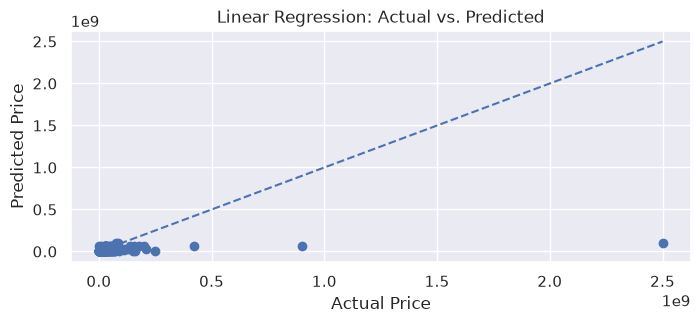

In [18]:
actual_predicted('Linear Regression', y_test, y_test_pred)

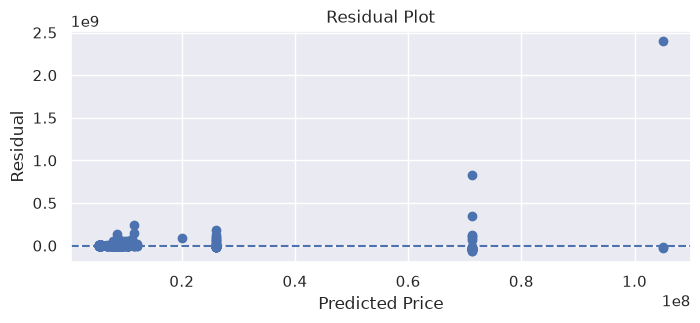

In [19]:
residuals('Linear Regression', y_test, y_test_pred)

In [20]:
pd.DataFrame({'y_test': y_test, 'y_test_prepd': y_test_pred})

,y_test,y_test_prepd
1287,1376000.0,9.439982e+06
52,11757000.0,5.720233e+06
1090,148000000.0,2.610445e+07
1177,26000000.0,1.026456e+07
262,9153000.0,5.357216e+06
...,...,...
20,5251000.0,5.720233e+06
294,32184000.0,7.122047e+07
242,32568000.0,7.122047e+07
485,2688000.0,7.051422e+06


The linear regression model performs poorly with a MAE of Php. 28 million. This will set as a baseline for our other model.

#### Random Forest

In [21]:
rf_model = RandomForestRegressor(random_state=73, n_jobs=-1)

In [22]:
rf_pipe = Pipeline([
    ('final_process', FinalProcessor()),
    ('kmeans', KMeansCluster()),
    ('target_encoder', target_encoder),
    ('model', rf_model)
])

In [23]:
# Baseline Random Forest with no CV
rf_pipe.fit(X_train, y_train)
rf_train_pred = rf_pipe.predict(X_train)
rf_test_pred = rf_pipe.predict(X_test)

evaluate_model('Random Forest', y_train, rf_train_pred, y_test, rf_test_pred)

,Model,MAE,RMSE,R-squared
0,Random Forest - Train,3.567146e+06,1.508250e+07,0.964721
1,Random Forest - Test,1.576515e+07,1.115202e+08,0.509796


The baseline random forest produced an MAE of Php. 15 million which is already better than the linear regression results.

In [24]:
# Performing GridSearch

param_grid = {
    'model__n_estimators': [200, 400, 500],
    'model__max_depth': [None, 10, 20, 25],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

rf_grid = GridSearchCV(estimator=rf_pipe, param_grid=param_grid, cv=5, scoring='neg_mean_absolute_error', n_jobs=1, verbose=1)
rf_grid.fit(X_train, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=73))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], 'model__n_estimators': [200, 400, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple me

In [25]:
rf_grid.best_params_

{'model__max_depth': 20,
 'model__min_samples_leaf': 1,
 'model__min_samples_split': 2,
 'model__n_estimators': 500}

In [26]:
print(f'Best CV MAE: {-rf_grid.best_score_:,.0f}')

Best CV MAE: 10,535,071


best_rf = rf_grid.best_estimator_
save_model(best_rf, 'Random-Forest.pkl')

In [27]:
random_forest = load_model('Random-Forest.pkl')

In [28]:
y_train_pred = random_forest.predict(X_train)
y_test_pred = random_forest.predict(X_test)

rf_results = evaluate_model('Linear Regression', y_train, y_train_pred, y_test, y_test_pred)
results = pd.concat([results, rf_results], ignore_index=True)
results

,Model,MAE,RMSE,R-squared
0,Linear Regression - Train,2.527114e+07,7.373122e+07,0.156921
1,Linear Regression - Test,2.812175e+07,1.534690e+08,0.071651
2,Linear Regression - Train,3.554640e+06,1.461827e+07,0.966860
3,Linear Regression - Test,1.565063e+07,1.127374e+08,0.499037


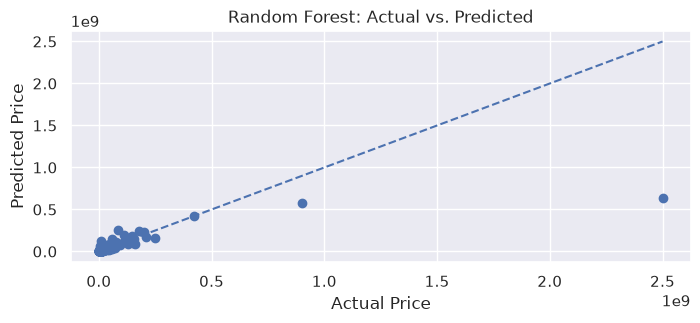

In [29]:
actual_predicted('Random Forest', y_test, y_test_pred)

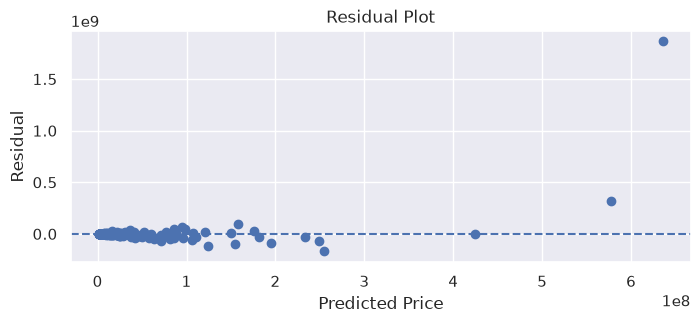

In [30]:
residuals('Random Forest', y_test, y_test_pred)

The random forest plot for actual vs predicted shows that most houses are clustered near the diagonal which means that actual is close with the predicted price. However, the model is poor in predicting very expensive houses, where the actual 2.5 Billion is only predicted around 600 Million.

#### XGBoost

In [31]:
xgb_model = XGBRegressor(random_state=73, n_jobs=-1)

In [32]:
xgb_pipe = Pipeline([
    ('final_process', FinalProcessor()),
    ('kmeans', KMeansCluster()),
    ('target_encoder', target_encoder),
    ('model', xgb_model)
])

In [33]:
# Baseline XGBoost with no CV
xgb_pipe.fit(X_train, y_train)
xgb_train_pred = xgb_pipe.predict(X_train)
xgb_test_pred = xgb_pipe.predict(X_test)

evaluate_model('XGBoost', y_train, xgb_train_pred, y_test, xgb_test_pred)

,Model,MAE,RMSE,R-squared
0,XGBoost - Train,5.937448e+05,1.020168e+06,0.999839
1,XGBoost - Test,1.546723e+07,1.067607e+08,0.550745


XGBoost shows around Php. 15 million MAE for the baseline model with no GridSearch.

In [34]:
param_grid = {
    "model__n_estimators": [200, 400, 500],
    "model__max_depth": [3, 6],
    "model__learning_rate": [0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

xgb_grid = GridSearchCV(xgb_pipe, param_grid, cv=5, scoring='neg_mean_absolute_error', n_jobs=1, verbose=1)
xgb_grid.fit(X_train, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__colsample_bytree': [0.8, 1.0], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3, 6], 'model__n_estimators': [200, 400, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple

In [35]:
xgb_grid.best_params_

{'model__colsample_bytree': 0.8,
 'model__learning_rate': 0.05,
 'model__max_depth': 6,
 'model__n_estimators': 500,
 'model__subsample': 0.8}

In [36]:
print(f'Best CV MAE: {-xgb_grid.best_score_:,.0f}')

Best CV MAE: 9,558,047


best_xgb = xgb_grid.best_estimator_
save_model(best_xgb, 'XGBoost.pkl')

In [37]:
xgboost = load_model('XGBoost.pkl')

In [38]:
y_train_pred = xgboost.predict(X_train)
y_test_pred = xgboost.predict(X_test)

xgb_results = evaluate_model('XGBoost', y_train, y_train_pred, y_test, y_test_pred)
results = pd.concat([results, xgb_results], ignore_index=True)
results

,Model,MAE,RMSE,R-squared
0,Linear Regression - Train,2.527114e+07,7.373122e+07,0.156921
1,Linear Regression - Test,2.812175e+07,1.534690e+08,0.071651
2,Linear Regression - Train,3.554640e+06,1.461827e+07,0.966860
3,Linear Regression - Test,1.565063e+07,1.127374e+08,0.499037
4,XGBoost - Train,7.810432e+05,1.231435e+06,0.999765
5,XGBoost - Test,1.330509e+07,1.044308e+08,0.570140


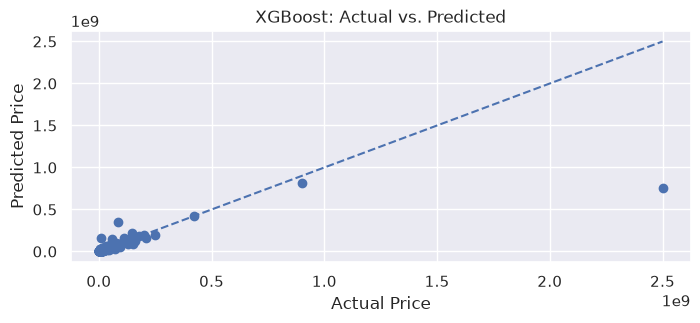

In [39]:
actual_predicted('XGBoost', y_test, y_test_pred)

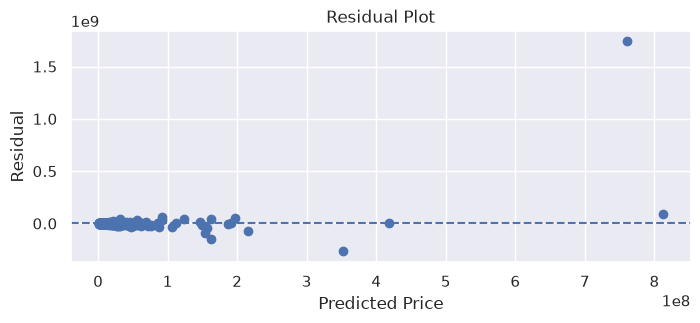

In [40]:
residuals('XGBoost', y_test, y_test_pred)

XGBoost performed slightly better than the Random Forest with Php. 13 million MAE. The same observations can be seen with their plots with slightly closer points for XGBoost with the diagnoal. 

## Conclusion

The modelling results show that both the Random Forest and XGBoost models are capable of capturing the general relationship between the House Prices and the property characteristics. Both models performed better than the baseline linear regression model.

However, both tree-models exhibit a similar limitation which is they underpredicted the most expensive houses in the data that are very far from the distribution. The behavior is likely due to the very skewed price distribution and only a small number of luxury properties the model can learn to. 

The residual analysis shows that the model can predict lower-priced houses generally but the prediction error increases for the higher-priced houses. Therefore, while the model can be used to predict house prices generally, the predictions for extreme luxury properties must be treated with great uncertainty.

Overall, the project showed that machine learning can be used to predict PH House Prices using property characteristics, geographic information, and engineered features.